In [1]:
import pandas as pd

url_dataset = (
    "https://raw.githubusercontent.com/nurhikam/mkb-ml-project/"
    "main/kasus/05-segmentasi-umkm/data/raw.csv"
)

df_raw = pd.read_csv(url_dataset)

print("Jumlah baris :", df_raw.shape[0])
print("Jumlah kolom :", df_raw.shape[1])

display(df_raw.head(15))

Jumlah baris : 10150
Jumlah kolom : 12


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5
5,PLG-02982,2025-02-05,30.0,Coblong,toko,ewallet,kopi,3,112200,114,45,4.0
6,PLG-03865,2024-07-13,25.0,Lengkong,gofood,tunai,roti,3,106200,150,67,3.7
7,PLG-08268,2026-02-02,NaN,Buahbatu,grabfood,ewallet,kopi,2,50500,108,37,3.8
8,PLG-07385,2025-09-22,29.0,Coblong,toko,tunai,roti,6,292800,42,64,3.9
9,PLG-05361,2025-05-16,18.0,Cibeunying Kidul,shopeefood,ewallet,paket_snack,10,231500,18,78,NaN


In [2]:
print("Daftar kolom:")
for nomor, kolom in enumerate(df_raw.columns, start=1):
    print(f"{nomor}. {kolom}")

print("\nInformasi dataset:")
df_raw.info()

Daftar kolom:
1. id_pelanggan
2. tanggal_daftar
3. umur
4. kecamatan
5. channel_utama
6. metode_bayar
7. kategori_favorit
8. jumlah_transaksi_6bln
9. total_belanja_rp
10. hari_sejak_transaksi_terakhir
11. persen_pakai_promo
12. rating_rata

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_pelanggan                   10150 non-null  object 
 1   tanggal_daftar                 10150 non-null  object 
 2   umur                           9942 non-null   float64
 3   kecamatan                      10150 non-null  object 
 4   channel_utama                  10150 non-null  object 
 5   metode_bayar                   10150 non-null  object 
 6   kategori_favorit               10150 non-null  object 
 7   jumlah_transaksi_6bln          10150 non-null  int64  
 8   total_belanja_rp          

# **Pemeriksaan Kualitas Data**

Nilai Kosong dan Duplikasi

In [3]:
# Ringkasan nilai kosong per kolom
tabel_missing = pd.DataFrame({
    "Jumlah Kosong": df_raw.isna().sum(),
    "Persentase (%)": df_raw.isna().mean() * 100
})

display(
    tabel_missing
    .sort_values("Jumlah Kosong", ascending=False)
    .round(2)
)

# Duplikat seluruh isi baris
print(
    "Baris duplikat penuh setelah kemunculan pertama:",
    df_raw.duplicated().sum()
)

# ID yang muncul lagi setelah kemunculan pertama
print(
    "Kemunculan ID berulang setelah kemunculan pertama:",
    df_raw["id_pelanggan"].duplicated().sum()
)

print(
    "Jumlah ID pelanggan unik:",
    df_raw["id_pelanggan"].nunique()
)

# Contoh baris dengan ID yang berulang
mask_id_berulang = df_raw["id_pelanggan"].duplicated(keep=False)

print("\nContoh data dengan ID pelanggan berulang:")
display(
    df_raw.loc[mask_id_berulang]
    .sort_values("id_pelanggan")
    .head(12)
)

,Jumlah Kosong,Persentase (%)
rating_rata,812,8.00
umur,208,2.05
tanggal_daftar,0,0.00
id_pelanggan,0,0.00
kecamatan,0,0.00
channel_utama,0,0.00
kategori_favorit,0,0.00
metode_bayar,0,0.00
jumlah_transaksi_6bln,0,0.00
total_belanja_rp,0,0.00


Baris duplikat penuh setelah kemunculan pertama: 90
Kemunculan ID berulang setelah kemunculan pertama: 150
Jumlah ID pelanggan unik: 10000

Contoh data dengan ID pelanggan berulang:


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
3145,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
5398,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
95,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
6998,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
1255,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.2
8828,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.2
3655,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
9620,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
1559,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6
9524,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6


In [4]:
# Salinan pemeriksaan tanpa duplikat penuh.
# df_raw tetap utuh.
df_cek = df_raw.drop_duplicates().copy()

# Ambil semua baris yang ID-nya masih berulang
mask_berulang = df_cek["id_pelanggan"].duplicated(keep=False)
data_id_berulang = df_cek.loc[mask_berulang].copy()

print("Jumlah baris setelah duplikat penuh disisihkan:", len(df_cek))
print(
    "Jumlah ID yang masih memiliki beberapa baris:",
    data_id_berulang["id_pelanggan"].nunique()
)

# Cari kolom yang nilainya berbeda pada setiap ID
kolom_diperiksa = [
    kolom for kolom in df_cek.columns
    if kolom != "id_pelanggan"
]

jumlah_nilai_unik = (
    data_id_berulang
    .groupby("id_pelanggan")[kolom_diperiksa]
    .nunique(dropna=False)
)

kolom_berbeda = jumlah_nilai_unik.gt(1)

ringkasan_perbedaan = pd.DataFrame({
    "Jumlah ID dengan nilai berbeda": kolom_berbeda.sum()
})

print("\nKolom yang berbeda pada ID berulang:")
display(
    ringkasan_perbedaan[
        ringkasan_perbedaan["Jumlah ID dengan nilai berbeda"] > 0
    ].sort_values("Jumlah ID dengan nilai berbeda", ascending=False)
)

print("\nContoh baris yang perlu diperiksa:")
display(
    data_id_berulang
    .sort_values("id_pelanggan")
    .head(12)
)

Jumlah baris setelah duplikat penuh disisihkan: 10060
Jumlah ID yang masih memiliki beberapa baris: 60

Kolom yang berbeda pada ID berulang:


,Jumlah ID dengan nilai berbeda
hari_sejak_transaksi_terakhir,60



Contoh baris yang perlu diperiksa:


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
1255,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.2
8828,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.2
7697,PLG-00276,2024-03-09,25.0,Arcamanik,gofood,transfer,paket_snack,9,398800,12,83,3.5
1902,PLG-00276,2024-03-09,25.0,Arcamanik,gofood,transfer,paket_snack,9,398800,13,83,3.5
4168,PLG-00335,2025-09-30,24.0,Bandung Wetan,gofood,tunai,paket_snack,13,422200,10,90,4.6
225,PLG-00335,2025-09-30,24.0,Bandung Wetan,gofood,tunai,paket_snack,13,422200,11,90,4.6
5820,PLG-00429,2024-11-19,26.0,Cibeunying Kidul,toko,qris,paket_snack,16,570200,18,77,4.4
10007,PLG-00429,2024-11-19,26.0,Cibeunying Kidul,toko,qris,paket_snack,16,570200,17,77,4.4
2262,PLG-00607,2024-10-17,19.0,Sukajadi,grabfood,qris,kopi,3,139100,114,22,3.9
10047,PLG-00607,2024-10-17,19.0,Sukajadi,grabfood,qris,kopi,3,139100,113,22,3.9


In [5]:
# Ringkasan nilai hari pada setiap pelanggan yang ID-nya berulang
ringkasan_selisih = (
    data_id_berulang
    .groupby("id_pelanggan")["hari_sejak_transaksi_terakhir"]
    .agg(
        Jumlah_Baris="size",
        Minimum="min",
        Maksimum="max"
    )
)

ringkasan_selisih["Selisih_Hari"] = (
    ringkasan_selisih["Maksimum"]
    - ringkasan_selisih["Minimum"]
)

print("Contoh perbedaan per pelanggan:")
display(ringkasan_selisih.head(10))

print("\nJumlah pelanggan berdasarkan selisih hari:")
display(
    ringkasan_selisih["Selisih_Hari"]
    .value_counts()
    .sort_index()
    .rename_axis("Selisih Hari")
    .reset_index(name="Jumlah Pelanggan")
)

print(
    "\nJumlah ID dengan nilai hari negatif:",
    (ringkasan_selisih["Minimum"] < 0).sum()
)

Contoh perbedaan per pelanggan:


,Jumlah_Baris,Minimum,Maksimum,Selisih_Hari
id_pelanggan,,,,
PLG-00079,2,10,11,1
PLG-00276,2,12,13,1
PLG-00335,2,10,11,1
PLG-00429,2,17,18,1
PLG-00607,2,113,114,1
PLG-00801,2,223,224,1
PLG-00923,2,170,171,1
PLG-01179,2,3,4,1
PLG-01340,2,10,11,1



Jumlah pelanggan berdasarkan selisih hari:


,Selisih Hari,Jumlah Pelanggan
0,1,60



Jumlah ID dengan nilai hari negatif: 0


# **Pembersihan Data**

In [6]:
# Mulai dari data mentah agar sel aman dijalankan ulang
df_tanpa_duplikat = df_raw.drop_duplicates().copy()

# Pastikan semua kolom selain nilai hari konsisten per pelanggan
kolom_lain = [
    kolom for kolom in df_tanpa_duplikat.columns
    if kolom not in [
        "id_pelanggan",
        "hari_sejak_transaksi_terakhir"
    ]
]

cek_konsistensi = (
    df_tanpa_duplikat
    .groupby("id_pelanggan")[kolom_lain]
    .nunique(dropna=False)
)

assert not cek_konsistensi.gt(1).any().any(), (
    "Ada perbedaan pada kolom lain. Periksa sebelum menggabungkan."
)

# Hitung median hari untuk setiap pelanggan
median_hari = (
    df_tanpa_duplikat
    .groupby("id_pelanggan")["hari_sejak_transaksi_terakhir"]
    .median()
)

# Ambil satu baris per ID, lalu gunakan median hari
df_clean = (
    df_tanpa_duplikat
    .drop_duplicates(subset="id_pelanggan")
    .copy()
)

df_clean["hari_sejak_transaksi_terakhir"] = (
    df_clean["id_pelanggan"].map(median_hari)
)

df_clean = df_clean.reset_index(drop=True)

print("Jumlah baris awal:", len(df_raw))
print("Setelah menghapus duplikat penuh:", len(df_tanpa_duplikat))
print("Setelah penggabungan per pelanggan:", len(df_clean))
print("Sisa ID berulang:", df_clean["id_pelanggan"].duplicated().sum())

print("\nContoh hasil penyatuan catatan dengan ID pelanggan yang sama:")
display(
    df_clean.loc[
        df_clean["id_pelanggan"].isin(ringkasan_selisih.index),
        ["id_pelanggan", "hari_sejak_transaksi_terakhir"]
    ].head(10)
)

Jumlah baris awal: 10150
Setelah menghapus duplikat penuh: 10060
Setelah penggabungan per pelanggan: 10000
Sisa ID berulang: 0

Contoh hasil penyatuan catatan dengan ID pelanggan yang sama:


,id_pelanggan,hari_sejak_transaksi_terakhir
41,PLG-05698,170.5
47,PLG-04593,22.5
186,PLG-08100,7.5
225,PLG-00335,10.5
297,PLG-02871,17.5
331,PLG-07379,5.5
431,PLG-00923,170.5
462,PLG-04668,12.5
561,PLG-03429,167.5
826,PLG-03467,27.5


In [7]:
# Salinan teks untuk pemeriksaan, belum mengubah df_clean
belanja_teks = df_clean["total_belanja_rp"].astype("string").str.strip()

# Kelompokkan format yang ditemukan
format_polos = belanja_teks.str.fullmatch(r"-?\d+", na=False)

format_rupiah = belanja_teks.str.fullmatch(
    r"(?i)Rp\s*-?\d{1,3}(?:\.\d{3})+",
    na=False
)

format_lain = (
    belanja_teks.notna()
    & ~format_polos
    & ~format_rupiah
)

ringkasan_format = pd.DataFrame({
    "Format": [
        "Angka bulat tanpa pemisah",
        "Rp dengan titik pemisah ribuan",
        "Format lain yang perlu diperiksa",
        "Nilai kosong"
    ],
    "Jumlah": [
        format_polos.sum(),
        format_rupiah.sum(),
        format_lain.sum(),
        belanja_teks.isna().sum()
    ]
})

display(ringkasan_format)

print("\nContoh nilai dengan format rupiah:")
display(
    df_clean.loc[
        format_rupiah,
        ["id_pelanggan", "total_belanja_rp"]
    ].head(10)
)

print("\nContoh format lain:")
display(
    df_clean.loc[
        format_lain,
        ["id_pelanggan", "total_belanja_rp"]
    ].head(20)
)

,Format,Jumlah
0,Angka bulat tanpa pemisah,9500
1,Rp dengan titik pemisah ribuan,500
2,Format lain yang perlu diperiksa,0
3,Nilai kosong,0



Contoh nilai dengan format rupiah:


,id_pelanggan,total_belanja_rp
1,PLG-06930,Rp 365.100
29,PLG-06885,Rp 446.400
39,PLG-05123,Rp 1.044.300
50,PLG-09252,Rp 59.700
54,PLG-01775,Rp 103.400
77,PLG-02348,Rp 94.500
102,PLG-04970,Rp 149.600
121,PLG-04854,Rp 264.100
150,PLG-02273,Rp 1.558.700
176,PLG-05949,Rp 2.198.900



Contoh format lain:


,id_pelanggan,total_belanja_rp


Konversi Total Belanja Menjadi Numerik

In [8]:
# Gunakan hasil pemeriksaan format dari tahap sebelumnya
belanja_sebelum = belanja_teks.copy()

# Hapus awalan Rp dan titik pemisah ribuan
belanja_rapi = (
    belanja_sebelum
    .str.replace(r"(?i)^Rp\s*", "", regex=True)
    .str.replace(".", "", regex=False)
)

# Konversi teks menjadi angka
belanja_numerik = pd.to_numeric(belanja_rapi, errors="coerce")

# Periksa kegagalan konversi sebelum memperbarui df_clean
gagal_konversi = belanja_sebelum.notna() & belanja_numerik.isna()

print("Jumlah nilai gagal dikonversi:", gagal_konversi.sum())

assert not gagal_konversi.any(), (
    "Ada nilai yang gagal dikonversi. Periksa sebelum melanjutkan."
)

# Simpan sebagai bilangan bulat rupiah
df_clean["total_belanja_rp"] = belanja_numerik.astype("int64")

# Tampilkan contoh perubahan pada nilai yang sebelumnya memakai Rp
perbandingan_belanja = pd.DataFrame({
    "Sebelum": belanja_sebelum,
    "Sesudah": df_clean["total_belanja_rp"]
})

display(perbandingan_belanja.loc[format_rupiah].head(10))

print("Tipe data setelah konversi:", df_clean["total_belanja_rp"].dtype)
print("Jumlah nilai kosong:", df_clean["total_belanja_rp"].isna().sum())
print("Jumlah baris:", len(df_clean))

# Nilai negatif ditandai untuk pemeriksaan, belum diubah
print(
    "Jumlah total belanja negatif:",
    (df_clean["total_belanja_rp"] < 0).sum()
)

display(df_clean.head(15))

Jumlah nilai gagal dikonversi: 0


,Sebelum,Sesudah
1,Rp 365.100,365100
29,Rp 446.400,446400
39,Rp 1.044.300,1044300
50,Rp 59.700,59700
54,Rp 103.400,103400
77,Rp 94.500,94500
102,Rp 149.600,149600
121,Rp 264.100,264100
150,Rp 1.558.700,1558700
176,Rp 2.198.900,2198900


Tipe data setelah konversi: int64
Jumlah nilai kosong: 0
Jumlah baris: 10000
Jumlah total belanja negatif: 0


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7.0,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,365100,10.0,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2.0,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7.0,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13.0,10,4.5
5,PLG-02982,2025-02-05,30.0,Coblong,toko,ewallet,kopi,3,112200,114.0,45,4.0
6,PLG-03865,2024-07-13,25.0,Lengkong,gofood,tunai,roti,3,106200,150.0,67,3.7
7,PLG-08268,2026-02-02,NaN,Buahbatu,grabfood,ewallet,kopi,2,50500,108.0,37,3.8
8,PLG-07385,2025-09-22,29.0,Coblong,toko,tunai,roti,6,292800,42.0,64,3.9
9,PLG-05361,2025-05-16,18.0,Cibeunying Kidul,shopeefood,ewallet,paket_snack,10,231500,18.0,78,NaN


Pemeriksaan nilai numerik

In [9]:
kolom_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

# Ringkasan rentang dan nilai kosong
ringkasan_numerik = pd.DataFrame({
    "Minimum": df_clean[kolom_numerik].min(),
    "Maksimum": df_clean[kolom_numerik].max(),
    "Jumlah Kosong": df_clean[kolom_numerik].isna().sum()
})

display(ringkasan_numerik)

# Pemeriksaan berdasarkan makna masing-masing kolom
pemeriksaan = {
    "Umur negatif":
        df_clean["umur"] < 0,

    "Jumlah transaksi negatif":
        df_clean["jumlah_transaksi_6bln"] < 0,

    "Total belanja negatif":
        df_clean["total_belanja_rp"] < 0,

    "Hari sejak transaksi terakhir negatif":
        df_clean["hari_sejak_transaksi_terakhir"] < 0,

    "Persentase promo di luar 0–100":
        (df_clean["persen_pakai_promo"] < 0)
        | (df_clean["persen_pakai_promo"] > 100),

    "Rating terisi di luar 1–5":
        df_clean["rating_rata"].notna()
        & ~df_clean["rating_rata"].between(1, 5)
}

tabel_pemeriksaan = pd.DataFrame({
    "Pemeriksaan": list(pemeriksaan.keys()),
    "Jumlah Baris": [
        kondisi.sum() for kondisi in pemeriksaan.values()
    ]
})

display(tabel_pemeriksaan)

,Minimum,Maksimum,Jumlah Kosong
umur,0.0,120.0,200
jumlah_transaksi_6bln,1.0,56.0,0
total_belanja_rp,11900.0,3424200.0,0
hari_sejak_transaksi_terakhir,0.0,225.0,0
persen_pakai_promo,0.0,100.0,0
rating_rata,2.0,5.0,800


,Pemeriksaan,Jumlah Baris
0,Umur negatif,0
1,Jumlah transaksi negatif,0
2,Total belanja negatif,0
3,Hari sejak transaksi terakhir negatif,0
4,Persentase promo di luar 0–100,0
5,Rating terisi di luar 1–5,0


Pemeriksaan Lanjutan Umur dan Waktu Transaksi

In [10]:
# Tampilkan frekuensi setiap umur tanpa mengubah data
print("Jumlah pelanggan untuk setiap nilai umur:")
display(
    df_clean["umur"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Umur")
    .reset_index(name="Jumlah Pelanggan")
)

# Ambang 181 hari hanya untuk pemeriksaan:
# Januari–Juni 2026 berjumlah 181 hari.
# Definisi periode yang tepat tetap perlu mengikuti sumber data.
mask_hari_panjang = (
    df_clean["hari_sejak_transaksi_terakhir"] > 181
)

print(
    "\nPelanggan dengan transaksi terakhir lebih dari 181 hari:",
    mask_hari_panjang.sum()
)

display(
    df_clean.loc[
        mask_hari_panjang,
        [
            "id_pelanggan",
            "tanggal_daftar",
            "jumlah_transaksi_6bln",
            "hari_sejak_transaksi_terakhir"
        ]
    ].head(15)
)

Jumlah pelanggan untuk setiap nilai umur:


,Umur,Jumlah Pelanggan
0,0.0,27
1,1.0,20
2,16.0,547
3,17.0,156
4,18.0,199
5,19.0,231
6,20.0,306
7,21.0,321
8,22.0,357
9,23.0,432



Pelanggan dengan transaksi terakhir lebih dari 181 hari: 55


,id_pelanggan,tanggal_daftar,jumlah_transaksi_6bln,hari_sejak_transaksi_terakhir
129,PLG-06375,2024-08-03,3,185.0
143,PLG-05816,2025-04-18,1,182.0
482,PLG-06520,2025-06-10,1,191.0
629,PLG-01801,2024-03-07,2,197.0
883,PLG-08467,2024-10-30,3,205.0
1014,PLG-07889,2025-11-14,1,215.0
1223,PLG-01152,2025-07-22,1,195.0
1303,PLG-01889,2025-02-28,5,202.0
1456,PLG-05048,2024-09-14,3,197.0
1518,PLG-05093,2026-05-06,3,200.0


In [11]:
# Tabel audit terpisah dari data untuk pemodelan
audit_data = df_clean[
    [
        "id_pelanggan",
        "umur",
        "jumlah_transaksi_6bln",
        "hari_sejak_transaksi_terakhir"
    ]
].copy()

# Nilai umur yang ditandai berdasarkan hasil pemeriksaan
# Ini penanda untuk ditinjau, bukan keputusan bahwa semuanya salah.
audit_data["umur_perlu_ditinjau"] = (
    audit_data["umur"].isin([0, 1, 99, 120])
)

audit_data["umur_kosong"] = audit_data["umur"].isna()

# Dugaan ketidaksesuaian periode transaksi
audit_data["waktu_transaksi_perlu_ditinjau"] = (
    (audit_data["jumlah_transaksi_6bln"] > 0)
    & (audit_data["hari_sejak_transaksi_terakhir"] > 181)
)

kolom_penanda = [
    "umur_perlu_ditinjau",
    "umur_kosong",
    "waktu_transaksi_perlu_ditinjau"
]

ringkasan_audit = pd.DataFrame({
    "Jumlah Pelanggan": audit_data[kolom_penanda].sum()
})

ringkasan_audit["Persentase (%)"] = (
    ringkasan_audit["Jumlah Pelanggan"]
    / len(audit_data) * 100
).round(2)

display(ringkasan_audit)

print(
    "Pelanggan dengan umur dan waktu transaksi sama-sama ditandai:",
    (
        audit_data["umur_perlu_ditinjau"]
        & audit_data["waktu_transaksi_perlu_ditinjau"]
    ).sum()
)

print("Jumlah baris df_clean tetap:", len(df_clean))

,Jumlah Pelanggan,Persentase (%)
umur_perlu_ditinjau,100,1.00
umur_kosong,200,2.00
waktu_transaksi_perlu_ditinjau,55,0.55


Pelanggan dengan umur dan waktu transaksi sama-sama ditandai: 0
Jumlah baris df_clean tetap: 10000


Pemeriksaan Konsistensi Data Kategori

In [12]:
kolom_kategori = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

for kolom in kolom_kategori:
    print(f"\nKolom: {kolom}")
    print("Jumlah kategori unik:", df_clean[kolom].nunique())

    # repr membantu memperlihatkan spasi tersembunyi.
    # Contoh: 'toko' berbeda dengan 'toko '.
    tabel_kategori = (
        df_clean[kolom]
        .map(repr)
        .value_counts(dropna=False)
        .rename_axis("Nilai Asli")
        .reset_index(name="Jumlah Pelanggan")
    )

    display(tabel_kategori)


Kolom: kecamatan
Jumlah kategori unik: 15


,Nilai Asli,Jumlah Pelanggan
0,'Buahbatu',1030
1,'Cidadap',1018
2,'Sumur Bandung',989
3,'Arcamanik',984
4,'Sukajadi',971
5,'Bandung Wetan',969
6,'Antapani',968
7,'Lengkong',960
8,'Coblong',934
9,'Cibeunying Kidul',928



Kolom: channel_utama
Jumlah kategori unik: 4


,Nilai Asli,Jumlah Pelanggan
0,'toko',4603
1,'gofood',2138
2,'shopeefood',1681
3,'grabfood',1578



Kolom: metode_bayar
Jumlah kategori unik: 4


,Nilai Asli,Jumlah Pelanggan
0,'qris',4510
1,'tunai',2501
2,'ewallet',1952
3,'transfer',1037



Kolom: kategori_favorit
Jumlah kategori unik: 4


,Nilai Asli,Jumlah Pelanggan
0,'kopi',4119
1,'roti',3442
2,'kue_ulang_tahun',1239
3,'paket_snack',1200


In [13]:
# Simpan nilai sebelum dibersihkan untuk perbandingan
kecamatan_sebelum = df_clean["kecamatan"].copy()

# Rapikan spasi dan samakan huruf menjadi kecil
kecamatan_rapi = (
    df_clean["kecamatan"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
)

# Satukan singkatan dan variasi penulisan yang ditemukan
kecamatan_rapi = kecamatan_rapi.replace({
    "bdg wetan": "bandung wetan",
    "buah batu": "buahbatu"
})

# Gunakan kapital awal untuk nama kecamatan
df_clean["kecamatan"] = kecamatan_rapi.str.title()

# Rapikan tiga kolom kategori lainnya
for kolom in ["channel_utama", "metode_bayar", "kategori_favorit"]:
    df_clean[kolom] = (
        df_clean[kolom]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# Periksa perubahan
print("Kategori kecamatan sebelum:", kecamatan_sebelum.nunique())
print("Kategori kecamatan sesudah:", df_clean["kecamatan"].nunique())

display(
    df_clean["kecamatan"]
    .value_counts()
    .rename_axis("Kecamatan")
    .reset_index(name="Jumlah Pelanggan")
)

print("Jumlah baris tetap:", len(df_clean))
print("Jumlah kecamatan kosong:", df_clean["kecamatan"].isna().sum())

Kategori kecamatan sebelum: 15
Kategori kecamatan sesudah: 10


,Kecamatan,Jumlah Pelanggan
0,Buahbatu,1077
1,Sukajadi,1037
2,Bandung Wetan,1024
3,Cidadap,1018
4,Sumur Bandung,989
5,Arcamanik,984
6,Coblong,979
7,Antapani,968
8,Cibeunying Kidul,964
9,Lengkong,960


Jumlah baris tetap: 10000
Jumlah kecamatan kosong: 0


Pemeriksaan Format dan Rentang Tanggal Pendaftaran

In [14]:
# Konversi sementara untuk pemeriksaan
# Kolom asli di df_clean belum diubah
tanggal_cek = pd.to_datetime(
    df_clean["tanggal_daftar"],
    format="%Y-%m-%d",
    errors="coerce"
)

tanggal_acuan = pd.Timestamp("2026-06-30")

mask_gagal = (
    df_clean["tanggal_daftar"].notna()
    & tanggal_cek.isna()
)

mask_setelah_acuan = tanggal_cek > tanggal_acuan

print("Tanggal kosong pada data awal:",
      df_clean["tanggal_daftar"].isna().sum())
print("Tanggal gagal dikonversi:", mask_gagal.sum())
print("Tanggal pendaftaran paling awal:", tanggal_cek.min())
print("Tanggal pendaftaran paling akhir:", tanggal_cek.max())
print("Pendaftaran setelah tanggal acuan:",
      mask_setelah_acuan.sum())

print("\nContoh hasil konversi:")
display(
    pd.DataFrame({
        "Sebelum": df_clean["tanggal_daftar"],
        "Sesudah": tanggal_cek
    }).head(10)
)

print("\nBaris yang perlu diperiksa:")
display(
    df_clean.loc[
        mask_gagal | mask_setelah_acuan,
        ["id_pelanggan", "tanggal_daftar"]
    ].head(15)
)

Tanggal kosong pada data awal: 0
Tanggal gagal dikonversi: 0
Tanggal pendaftaran paling awal: 2024-01-13 00:00:00
Tanggal pendaftaran paling akhir: 2026-05-31 00:00:00
Pendaftaran setelah tanggal acuan: 0

Contoh hasil konversi:


,Sebelum,Sesudah
0,2025-10-10,2025-10-10
1,2026-05-19,2026-05-19
2,2024-02-28,2024-02-28
3,2025-11-22,2025-11-22
4,2025-07-31,2025-07-31
5,2025-02-05,2025-02-05
6,2024-07-13,2024-07-13
7,2026-02-02,2026-02-02
8,2025-09-22,2025-09-22
9,2025-05-16,2025-05-16



Baris yang perlu diperiksa:


,id_pelanggan,tanggal_daftar


In [15]:
df_clean["tanggal_daftar"] = tanggal_cek.copy()

print("Tipe data setelah konversi:",
      df_clean["tanggal_daftar"].dtype)

Tipe data setelah konversi: datetime64[ns]


Pemeriksaan Konsistensi Waktu Pelanggan

In [16]:
# Acuan akhir periode dataset
tanggal_acuan = pd.Timestamp("2026-06-30")

# Tabel pemeriksaan terpisah
cek_waktu = df_clean[
    [
        "id_pelanggan",
        "tanggal_daftar",
        "hari_sejak_transaksi_terakhir"
    ]
].copy()

# Lama pelanggan terdaftar sampai tanggal acuan
cek_waktu["lama_terdaftar_hari"] = (
    tanggal_acuan - cek_waktu["tanggal_daftar"]
).dt.days

# Tandai jika transaksi terakhir diperkirakan sebelum pendaftaran
mask_sebelum_daftar = (
    cek_waktu["hari_sejak_transaksi_terakhir"]
    > cek_waktu["lama_terdaftar_hari"]
)

print(
    "Jumlah pelanggan dengan transaksi terakhir sebelum pendaftaran:",
    mask_sebelum_daftar.sum()
)

print("\nContoh baris yang perlu ditinjau:")
display(cek_waktu.loc[mask_sebelum_daftar].head(15))

print("\nRentang lama terdaftar:")
print("Minimum:", cek_waktu["lama_terdaftar_hari"].min(), "hari")
print("Maksimum:", cek_waktu["lama_terdaftar_hari"].max(), "hari")

Jumlah pelanggan dengan transaksi terakhir sebelum pendaftaran: 284

Contoh baris yang perlu ditinjau:


,id_pelanggan,tanggal_daftar,hari_sejak_transaksi_terakhir,lama_terdaftar_hari
41,PLG-05698,2026-03-20,170.5,102
50,PLG-09252,2026-05-19,137.0,42
95,PLG-00047,2026-04-09,121.0,82
182,PLG-07078,2026-05-19,143.0,42
214,PLG-05717,2026-03-12,128.0,110
229,PLG-02173,2026-04-07,131.0,84
233,PLG-01579,2026-04-21,140.0,70
235,PLG-01928,2026-05-27,144.0,34
239,PLG-07734,2026-03-26,112.0,96
243,PLG-07493,2026-03-13,115.0,109



Rentang lama terdaftar:
Minimum: 30 hari
Maksimum: 899 hari


Ringkasan Akhir Pemeriksaan Data

In [17]:
# Tambahkan temuan waktu ke tabel audit berdasarkan ID pelanggan
id_sebelum_daftar = cek_waktu.loc[
    mask_sebelum_daftar, "id_pelanggan"
]

audit_data["transaksi_sebelum_daftar"] = (
    audit_data["id_pelanggan"].isin(id_sebelum_daftar)
)

# Periksa kondisi data setelah perapian
ringkasan_akhir = pd.DataFrame({
    "Tipe Data": df_clean.dtypes.astype(str),
    "Jumlah Kosong": df_clean.isna().sum(),
    "Persentase Kosong (%)": (
        df_clean.isna().mean() * 100
    ).round(2)
})

display(ringkasan_akhir)

print("Jumlah pelanggan:", len(df_clean))
print("Jumlah ID unik:", df_clean["id_pelanggan"].nunique())
print("Sisa ID berulang:", df_clean["id_pelanggan"].duplicated().sum())
print(
    "Transaksi sebelum pendaftaran:",
    audit_data["transaksi_sebelum_daftar"].sum()
)

,Tipe Data,Jumlah Kosong,Persentase Kosong (%)
id_pelanggan,object,0,0.0
tanggal_daftar,datetime64[ns],0,0.0
umur,float64,200,2.0
kecamatan,string,0,0.0
channel_utama,string,0,0.0
metode_bayar,string,0,0.0
kategori_favorit,string,0,0.0
jumlah_transaksi_6bln,int64,0,0.0
total_belanja_rp,int64,0,0.0
hari_sejak_transaksi_terakhir,float64,0,0.0


Jumlah pelanggan: 10000
Jumlah ID unik: 10000
Sisa ID berulang: 0
Transaksi sebelum pendaftaran: 284


Pembagian train test

In [18]:
from sklearn.model_selection import train_test_split

# Pastikan satu baris mewakili satu pelanggan
assert df_clean["id_pelanggan"].notna().all()
assert df_clean["id_pelanggan"].is_unique

# Pembagian acak yang bisa diulang dengan hasil sama
df_dev, df_test = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

df_dev = df_dev.copy()
df_test = df_test.copy()

# Pastikan tidak ada pelanggan yang masuk kedua bagian
id_beririsan = (
    set(df_dev["id_pelanggan"])
    & set(df_test["id_pelanggan"])
)

ringkasan_split = pd.DataFrame({
    "Bagian Data": ["Pengembangan", "Uji"],
    "Jumlah Pelanggan": [len(df_dev), len(df_test)],
    "Persentase (%)": [
        len(df_dev) / len(df_clean) * 100,
        len(df_test) / len(df_clean) * 100
    ]
})

display(ringkasan_split)

print("ID yang muncul di kedua bagian:", len(id_beririsan))

assert len(id_beririsan) == 0
assert len(df_dev) + len(df_test) == len(df_clean)

,Bagian Data,Jumlah Pelanggan,Persentase (%)
0,Pengembangan,8000,80.0
1,Uji,2000,20.0


ID yang muncul di kedua bagian: 0


# **EDA**

Distribusi Perilaku Belanja Pelanggan

,count,mean,std,min,25%,50%,75%,max
jumlah_transaksi_6bln,8000.0,12.60,11.70,1.0,3.0,8.0,21.00,56.0
total_belanja_rp,8000.0,698619.88,652562.04,11900.0,153775.0,431300.0,1152800.00,3424200.0
hari_sejak_transaksi_terakhir,8000.0,41.74,49.48,0.0,6.0,15.0,74.00,225.0
persen_pakai_promo,8000.0,38.33,27.93,0.0,16.0,28.0,64.25,100.0
rating_rata,7374.0,4.15,0.53,2.4,3.8,4.2,4.50,5.0


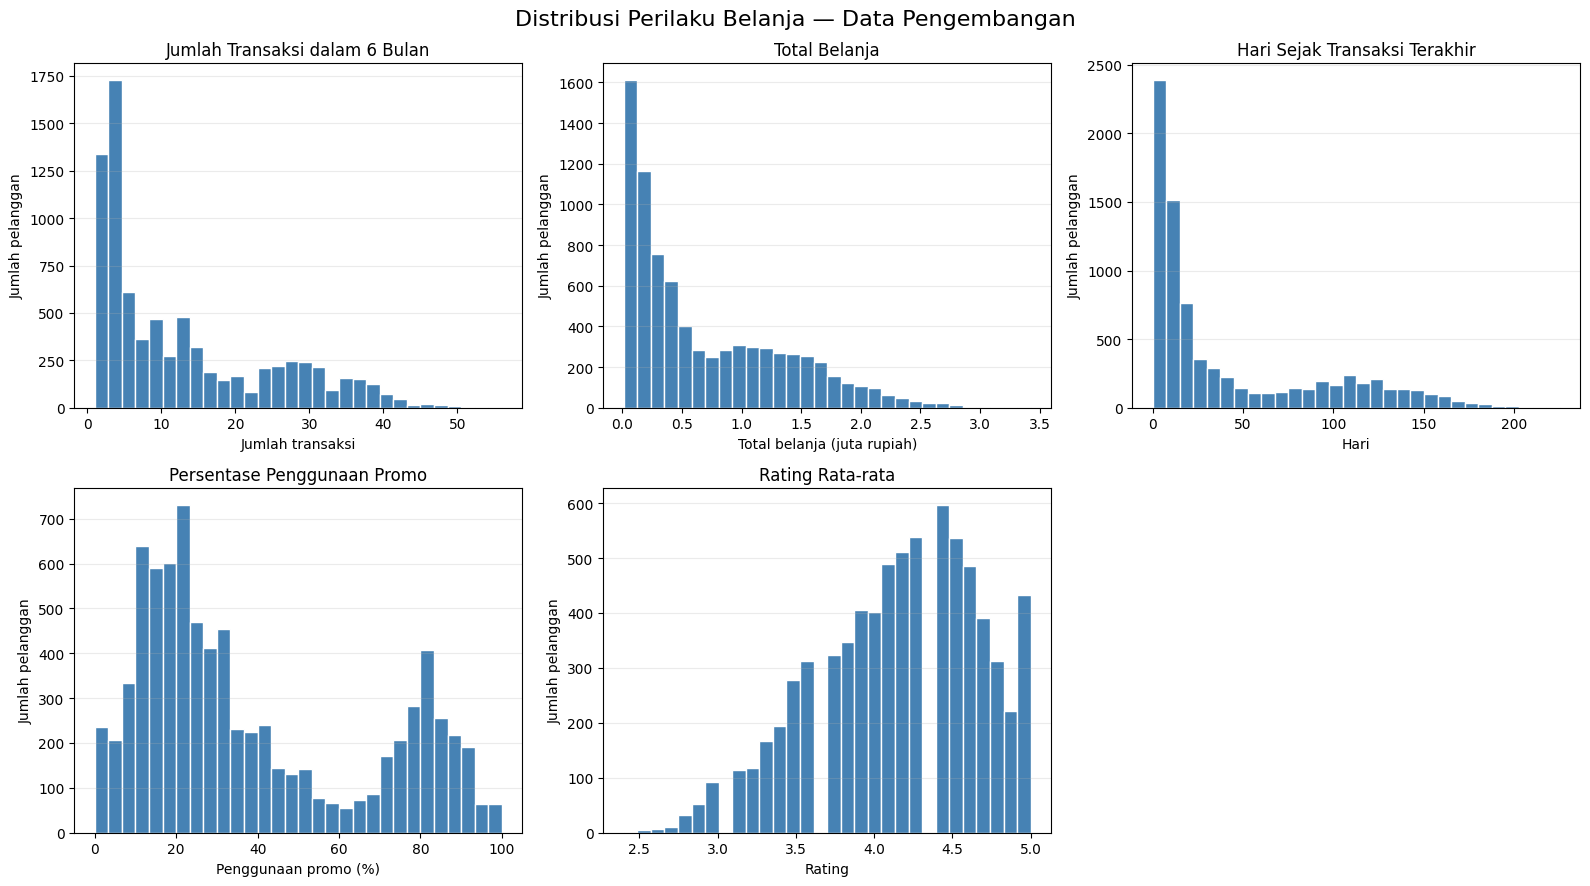

In [19]:
import matplotlib.pyplot as plt

kolom_perilaku = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

# Ringkasan statistik hanya dari data pengembangan
display(
    df_dev[kolom_perilaku]
    .describe()
    .T
    .round(2)
)

judul_grafik = [
    "Jumlah Transaksi dalam 6 Bulan",
    "Total Belanja",
    "Hari Sejak Transaksi Terakhir",
    "Persentase Penggunaan Promo",
    "Rating Rata-rata"
]

label_sumbu = [
    "Jumlah transaksi",
    "Total belanja (juta rupiah)",
    "Hari",
    "Penggunaan promo (%)",
    "Rating"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, kolom, judul, label in zip(
    axes, kolom_perilaku, judul_grafik, label_sumbu
):
    # Nilai kosong dilewati hanya saat menggambar.
    # Data asli tidak dihapus atau diisi.
    nilai = df_dev[kolom].dropna()

    # Ubah satuan tampilan agar angka rupiah mudah dibaca
    if kolom == "total_belanja_rp":
        nilai = nilai / 1_000_000

    ax.hist(
        nilai,
        bins=30,
        color="steelblue",
        edgecolor="white"
    )

    ax.set_title(judul)
    ax.set_xlabel(label)
    ax.set_ylabel("Jumlah pelanggan")
    ax.grid(axis="y", alpha=0.25)

# Lima grafik, sehingga panel keenam tidak digunakan
axes[5].axis("off")

fig.suptitle(
    "Distribusi Perilaku Belanja — Data Pengembangan",
    fontsize=16
)

plt.tight_layout()
plt.show()

Analisis Korelasi Antarvariabel Perilaku Belanja

Tabel korelasi antarvariabel:


,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
jumlah_transaksi_6bln,1.000,0.719,-0.598,-0.184,0.385
total_belanja_rp,0.719,1.000,-0.536,-0.461,0.403
hari_sejak_transaksi_terakhir,-0.598,-0.536,1.000,-0.097,-0.622
persen_pakai_promo,-0.184,-0.461,-0.097,1.000,0.057
rating_rata,0.385,0.403,-0.622,0.057,1.000


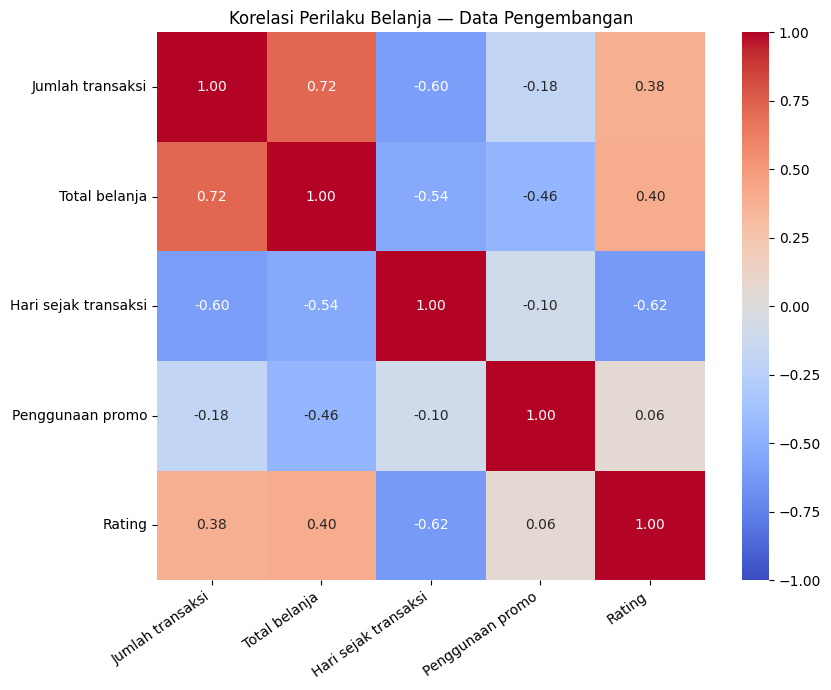

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Korelasi hanya menggunakan data pengembangan
korelasi_perilaku = df_dev[kolom_perilaku].corr(
    method="pearson"
)

print("Tabel korelasi antarvariabel:")
display(korelasi_perilaku.round(3))

# Label singkat agar heatmap mudah dibaca
label_fitur = [
    "Jumlah transaksi",
    "Total belanja",
    "Hari sejak transaksi",
    "Penggunaan promo",
    "Rating"
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    korelasi_perilaku,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=label_fitur,
    yticklabels=label_fitur
)

plt.title("Korelasi Perilaku Belanja — Data Pengembangan")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Penetapan Fitur Baseline

In [21]:
# Fitur untuk baseline clustering perilaku belanja
fitur_baseline = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

X_dev = df_dev[fitur_baseline].copy()

ringkasan_fitur = pd.DataFrame({
    "Tipe Data": X_dev.dtypes.astype(str),
    "Jumlah Kosong": X_dev.isna().sum(),
    "Jumlah Nilai Unik": X_dev.nunique()
})

display(ringkasan_fitur)

print("Ukuran data untuk pengembangan model:", X_dev.shape)
print("Jumlah pelanggan tetap:", len(X_dev))

,Tipe Data,Jumlah Kosong,Jumlah Nilai Unik
jumlah_transaksi_6bln,int64,0,53
total_belanja_rp,int64,0,6028
hari_sejak_transaksi_terakhir,float64,0,240
persen_pakai_promo,int64,0,101
rating_rata,float64,626,27


Ukuran data untuk pengembangan model: (8000, 5)
Jumlah pelanggan tetap: 8000


fungsi pembentuk Pipeline

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

def buat_pipeline_kmeans(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        ))
    ])

# K=2 hanya untuk menampilkan susunan pipeline.
# Model belum dilatih.
pipeline_contoh = buat_pipeline_kmeans(k=2)

display(pipeline_contoh)

print("Pipeline berhasil dibuat.")
print("Belum dilakukan pelatihan atau perubahan pada X_dev.")

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=2, n_init=20, random_state=42))])

Pipeline berhasil dibuat.
Belum dilakukan pelatihan atau perubahan pada X_dev.


Pelatihan Baseline dan Perbandingan Jumlah Cluster

K=2 selesai | Silhouette=0.3712
K=3 selesai | Silhouette=0.4646
K=4 selesai | Silhouette=0.4666
K=5 selesai | Silhouette=0.4256
K=6 selesai | Silhouette=0.3550
K=7 selesai | Silhouette=0.3456
K=8 selesai | Silhouette=0.2885
K=9 selesai | Silhouette=0.2858
K=10 selesai | Silhouette=0.2830


,K,Inertia,Silhouette Sampel,Cluster Terkecil,Cluster Terbesar
0,2,24534.8873,0.3712,3388,4612
1,3,14454.1661,0.4646,2002,3539
2,4,10347.9480,0.4666,1652,2323
3,5,9248.3690,0.4256,1067,2325
4,6,8233.9833,0.3550,1066,1980
5,7,7532.9051,0.3456,488,1982
6,8,6869.5526,0.2885,491,1296
7,9,6348.2568,0.2858,485,1224
8,10,5853.4701,0.2830,484,1003


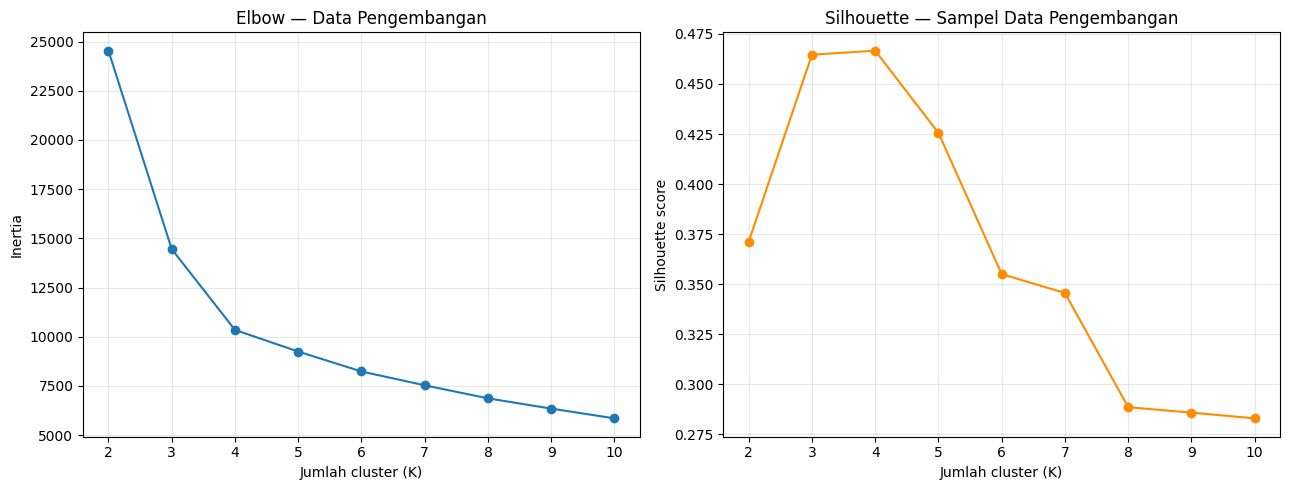

In [23]:
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

daftar_k = range(2, 11)
hasil_evaluasi_k = []
model_per_k = {}

# Sampel yang sama untuk evaluasi silhouette setiap K
# Membatasi biaya perhitungan; pelatihan tetap memakai 8.000 pelanggan
rng = np.random.default_rng(42)
indeks_sampel = rng.choice(
    len(X_dev),
    size=min(3000, len(X_dev)),
    replace=False
)

for k in daftar_k:
    pipeline = buat_pipeline_kmeans(k)

    # Imputer, scaler, dan K-Means dipelajari dari X_dev
    pipeline.fit(X_dev)

    label_cluster = pipeline.named_steps["kmeans"].labels_

    # Ambil data setelah imputasi dan scaling.
    # Silhouette dihitung dalam ruang yang dipakai K-Means.
    X_scaled = pipeline[:-1].transform(X_dev)

    skor_silhouette = silhouette_score(
        X_scaled[indeks_sampel],
        label_cluster[indeks_sampel]
    )

    ukuran_cluster = np.bincount(label_cluster, minlength=k)

    hasil_evaluasi_k.append({
        "K": k,
        "Inertia": pipeline.named_steps["kmeans"].inertia_,
        "Silhouette Sampel": skor_silhouette,
        "Cluster Terkecil": ukuran_cluster.min(),
        "Cluster Terbesar": ukuran_cluster.max()
    })

    # Simpan model agar tidak perlu melatih ulang saat memeriksa profil
    model_per_k[k] = pipeline

    print(f"K={k} selesai | Silhouette={skor_silhouette:.4f}")

tabel_evaluasi_k = pd.DataFrame(hasil_evaluasi_k)

display(tabel_evaluasi_k.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    tabel_evaluasi_k["K"],
    tabel_evaluasi_k["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow — Data Pengembangan")
axes[0].set_xlabel("Jumlah cluster (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    tabel_evaluasi_k["K"],
    tabel_evaluasi_k["Silhouette Sampel"],
    marker="o",
    color="darkorange"
)
axes[1].set_title("Silhouette — Sampel Data Pengembangan")
axes[1].set_xlabel("Jumlah cluster (K)")
axes[1].set_ylabel("Silhouette score")

for ax in axes:
    ax.set_xticks(list(daftar_k))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Perbandingan Profil Pelanggan pada K=3 dan K=4

In [24]:
profil_kandidat = {}

for k in [3, 4]:
    # Gunakan model yang sudah dilatih sebelumnya
    model = model_per_k[k]

    data_profil = df_dev.copy()

    # Prediksi mengikuti urutan baris data yang sedang digunakan
    data_profil["Cluster"] = model.predict(
        data_profil[fitur_baseline]
    )

    kelompok = data_profil.groupby("Cluster")

    # Median memakai nilai asli agar mudah ditafsirkan
    profil = kelompok[fitur_baseline].median()

    profil.insert(
        0, "Jumlah Pelanggan", kelompok.size()
    )

    profil.insert(
        1,
        "Persentase (%)",
        kelompok.size() / len(data_profil) * 100
    )

    # Tampilkan kelengkapan rating untuk mendampingi median
    profil["Rating Terisi"] = kelompok["rating_rata"].count()
    profil["Rating Kosong"] = (
        profil["Jumlah Pelanggan"] - profil["Rating Terisi"]
    )

    profil_kandidat[k] = profil

    print(f"\nProfil pelanggan untuk K = {k}")
    display(profil.round(2))


Profil pelanggan untuk K = 3


,Jumlah Pelanggan,Persentase (%),jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,Rating Terisi,Rating Kosong
Cluster,,,,,,,,,
0,2459,30.74,3.0,103100.0,109.0,34.0,3.6,2265,194
1,2002,25.02,11.0,334300.0,12.0,82.0,4.4,1832,170
2,3539,44.24,23.0,1240900.0,7.0,17.0,4.4,3277,262



Profil pelanggan untuk K = 4


,Jumlah Pelanggan,Persentase (%),jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,Rating Terisi,Rating Kosong
Cluster,,,,,,,,,
0,2323,29.04,3.0,99300.0,111.0,35.0,3.6,2147,176
1,2038,25.48,30.0,1414100.0,5.0,20.0,4.4,1879,159
2,1987,24.84,11.0,336100.0,12.0,82.0,4.4,1819,168
3,1652,20.65,5.0,893750.0,24.0,14.0,4.4,1529,123


Penetapan Model Baseline dan Nama Segmen

In [25]:
# Pilih model yang sudah dilatih, tanpa melatih ulang
k_baseline = 4
pipeline_baseline = model_per_k[k_baseline]

nama_segmen_baseline = {
    0: "Jarang bertransaksi dan lama tidak aktif",
    1: "Sering bertransaksi dengan belanja tinggi",
    2: "Sering menggunakan promo",
    3: "Frekuensi rendah dengan belanja relatif tinggi"
}

# Simpan hasil segmentasi data pengembangan
hasil_dev_baseline = df_dev.copy()

hasil_dev_baseline["Cluster"] = pipeline_baseline.predict(
    hasil_dev_baseline[fitur_baseline]
)

hasil_dev_baseline["Segmen"] = (
    hasil_dev_baseline["Cluster"].map(nama_segmen_baseline)
)

ringkasan_segmen = (
    hasil_dev_baseline
    .groupby(["Cluster", "Segmen"])
    .size()
    .reset_index(name="Jumlah Pelanggan")
)

ringkasan_segmen["Persentase (%)"] = (
    ringkasan_segmen["Jumlah Pelanggan"]
    / len(hasil_dev_baseline) * 100
).round(2)

display(ringkasan_segmen)

print("Jumlah pelanggan:", ringkasan_segmen["Jumlah Pelanggan"].sum())
print("Segmen tanpa nama:", hasil_dev_baseline["Segmen"].isna().sum())

,Cluster,Segmen,Jumlah Pelanggan,Persentase (%)
0,0,Jarang bertransaksi dan lama tidak aktif,2323,29.04
1,1,Sering bertransaksi dengan belanja tinggi,2038,25.48
2,2,Sering menggunakan promo,1987,24.84
3,3,Frekuensi rendah dengan belanja relatif tinggi,1652,20.65


Jumlah pelanggan: 8000
Segmen tanpa nama: 0


Visualisasi Profil Cluster Baseline

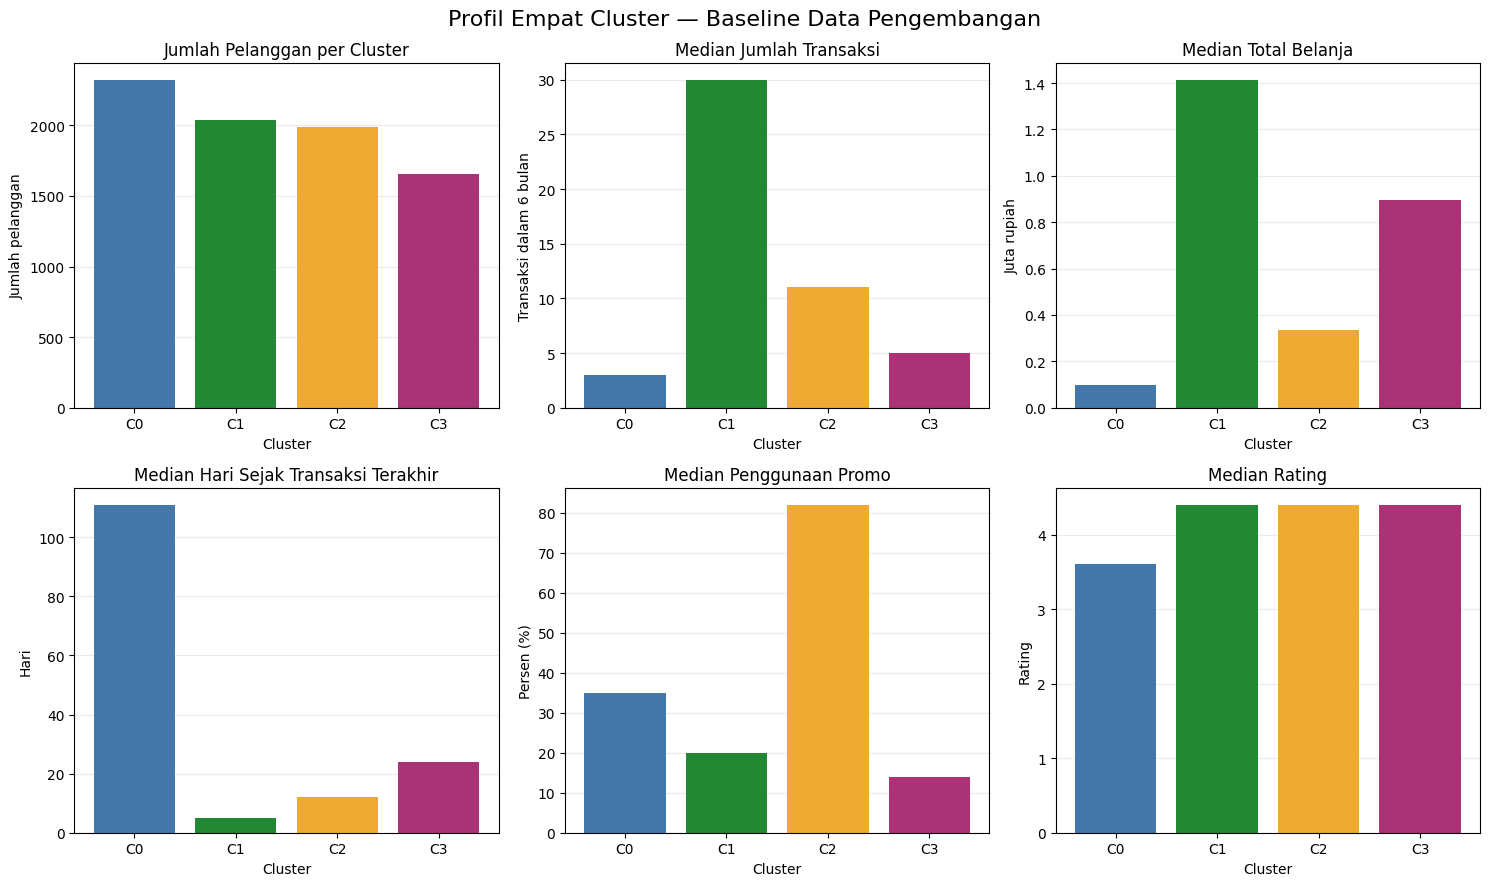

C0: Jarang bertransaksi dan lama tidak aktif
C1: Sering bertransaksi dengan belanja tinggi
C2: Sering menggunakan promo
C3: Frekuensi rendah dengan belanja relatif tinggi


In [26]:
import matplotlib.pyplot as plt

# Profil menggunakan nilai asli, sebelum imputasi dan scaling
profil_plot = (
    hasil_dev_baseline
    .groupby("Cluster")[fitur_baseline]
    .median()
    .sort_index()
)

jumlah_anggota = (
    hasil_dev_baseline.groupby("Cluster")
    .size()
    .reindex(profil_plot.index)
)

warna_cluster = ["#4477AA", "#228833", "#EEAA33", "#AA3377"]
label_cluster = [f"C{i}" for i in profil_plot.index]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

# Grafik jumlah anggota
axes[0].bar(label_cluster, jumlah_anggota, color=warna_cluster)
axes[0].set_title("Jumlah Pelanggan per Cluster")
axes[0].set_ylabel("Jumlah pelanggan")

judul = [
    "Median Jumlah Transaksi",
    "Median Total Belanja",
    "Median Hari Sejak Transaksi Terakhir",
    "Median Penggunaan Promo",
    "Median Rating"
]

satuan = [
    "Transaksi dalam 6 bulan",
    "Juta rupiah",
    "Hari",
    "Persen (%)",
    "Rating"
]

for ax, kolom, nama, unit in zip(
    axes[1:], fitur_baseline, judul, satuan
):
    nilai = profil_plot[kolom].copy()

    if kolom == "total_belanja_rp":
        nilai = nilai / 1_000_000

    ax.bar(label_cluster, nilai, color=warna_cluster)
    ax.set_title(nama)
    ax.set_ylabel(unit)

for ax in axes:
    ax.set_xlabel("Cluster")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Profil Empat Cluster — Baseline Data Pengembangan",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Keterangan nomor cluster
for nomor, nama in nama_segmen_baseline.items():
    print(f"C{nomor}: {nama}")

Percobaan Perbaikan Model

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

fitur_log = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir"
]

fitur_tanpa_log = [
    "persen_pakai_promo",
    "rating_rata"
]

# Preprocessing untuk fitur yang diberi transformasi log
proses_log = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

# Preprocessing untuk fitur lainnya
proses_biasa = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessing_log = ColumnTransformer([
    ("fitur_log", proses_log, fitur_log),
    ("fitur_biasa", proses_biasa, fitur_tanpa_log)
])

pipeline_log = Pipeline([
    ("preprocessing", preprocessing_log),
    ("kmeans", KMeans(
        n_clusters=4,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

# Latih hanya dengan data pengembangan
pipeline_log.fit(X_dev)

label_log = pipeline_log.predict(X_dev)
label_baseline = pipeline_baseline.predict(X_dev)

# Dua representasi data untuk evaluasi
X_scaled_baseline = pipeline_baseline[:-1].transform(X_dev)
X_scaled_log = pipeline_log[:-1].transform(X_dev)

# Gunakan sampel pelanggan yang sama seperti percobaan sebelumnya
hasil_perbandingan = []

for nama, label in [
    ("Baseline K=4", label_baseline),
    ("Log + scaling K=4", label_log)
]:
    ukuran = np.bincount(label, minlength=4)

    hasil_perbandingan.append({
        "Model": nama,
        "Silhouette ruang baseline": silhouette_score(
            X_scaled_baseline[indeks_sampel],
            label[indeks_sampel]
        ),
        "Silhouette ruang log": silhouette_score(
            X_scaled_log[indeks_sampel],
            label[indeks_sampel]
        ),
        "Cluster Terkecil": ukuran.min(),
        "Cluster Terbesar": ukuran.max()
    })

tabel_perbandingan_log = pd.DataFrame(hasil_perbandingan)
display(tabel_perbandingan_log.round(4))

,Model,Silhouette ruang baseline,Silhouette ruang log,Cluster Terkecil,Cluster Terbesar
0,Baseline K=4,0.4666,0.4445,1652,2323
1,Log + scaling K=4,0.4651,0.4883,1220,2444


In [28]:
# Salinan data pengembangan dengan cluster dari model log
hasil_dev_log = df_dev.copy()
hasil_dev_log["Cluster"] = label_log

# Profil menggunakan nilai asli, bukan nilai hasil log/scaling
grup_log = hasil_dev_log.groupby("Cluster")

profil_log = grup_log[fitur_baseline].median()

profil_log.insert(
    0, "Jumlah Pelanggan",
    grup_log.size()
)

profil_log.insert(
    1, "Persentase (%)",
    grup_log.size() / len(hasil_dev_log) * 100
)

# Median rating di atas hanya menggunakan rating yang tersedia
profil_log["Rating Terisi"] = grup_log["rating_rata"].count()
profil_log["Rating Kosong"] = (
    grup_log.size() - grup_log["rating_rata"].count()
)

print("Profil model baseline:")
display(profil_kandidat[4].round(2))

print("\nProfil model log + scaling:")
display(profil_log.round(2))

# Menunjukkan perpindahan anggota dari baseline ke model log
print("\nPerbandingan keanggotaan cluster:")
display(pd.crosstab(
    hasil_dev_baseline["Cluster"],
    hasil_dev_log["Cluster"],
    rownames=["Cluster Baseline"],
    colnames=["Cluster Log"]
))

Profil model baseline:


,Jumlah Pelanggan,Persentase (%),jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,Rating Terisi,Rating Kosong
Cluster,,,,,,,,,
0,2323,29.04,3.0,99300.0,111.0,35.0,3.6,2147,176
1,2038,25.48,30.0,1414100.0,5.0,20.0,4.4,1879,159
2,1987,24.84,11.0,336100.0,12.0,82.0,4.4,1819,168
3,1652,20.65,5.0,893750.0,24.0,14.0,4.4,1529,123



Profil model log + scaling:


,Jumlah Pelanggan,Persentase (%),jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,Rating Terisi,Rating Kosong
Cluster,,,,,,,,,
0,1220,15.25,4.0,1025650.0,30.0,13.0,4.4,1135,85
1,1969,24.61,11.0,337400.0,12.0,82.0,4.4,1802,167
2,2444,30.55,28.0,1299050.0,5.0,20.0,4.4,2257,187
3,2367,29.59,3.0,99200.0,110.0,35.0,3.6,2180,187



Perbandingan keanggotaan cluster:


Cluster Log,0,1,2,3
Cluster Baseline,,,,
0,11,0,1,2311
1,3,0,2035,0
2,0,1968,1,18
3,1206,1,407,38


In [29]:
from sklearn.base import clone
from sklearn.metrics import adjusted_rand_score

hasil_stabilitas = []

# Hasil model log sebelumnya sebagai pembanding
label_acuan = pipeline_log.predict(X_dev)

for seed in [0, 7, 21, 42, 99]:
    model_cek = clone(pipeline_log)

    model_cek.set_params(
        kmeans__random_state=seed
    )

    model_cek.fit(X_dev)
    label_cek = model_cek.predict(X_dev)

    hasil_stabilitas.append({
        "Random State": seed,
        "ARI terhadap model log awal": adjusted_rand_score(
            label_acuan, label_cek
        ),
        "Cluster Terkecil": pd.Series(label_cek).value_counts().min(),
        "Cluster Terbesar": pd.Series(label_cek).value_counts().max()
    })

tabel_stabilitas = pd.DataFrame(hasil_stabilitas)
display(tabel_stabilitas.round(4))

,Random State,ARI terhadap model log awal,Cluster Terkecil,Cluster Terbesar
0,0,1.0,1220,2444
1,7,1.0,1220,2444
2,21,1.0,1220,2444
3,42,1.0,1220,2444
4,99,1.0,1220,2444


In [30]:
# Tandai ketidaksesuaian periode pada data pengembangan saja
mask_periode = (
    (df_dev["jumlah_transaksi_6bln"] > 0)
    & (df_dev["hari_sejak_transaksi_terakhir"] > 181)
)

X_dev_periode = df_dev.loc[
    ~mask_periode, fitur_baseline
].copy()

# Model pembanding: konfigurasi sama, baris bertanda dikecualikan
pipeline_cek_periode = clone(pipeline_log)
pipeline_cek_periode.fit(X_dev_periode)

# Bandingkan kedua model pada pelanggan yang sama
label_awal = pipeline_log.predict(X_dev_periode)
label_pembanding = pipeline_cek_periode.predict(X_dev_periode)

ari_periode = adjusted_rand_score(
    label_awal, label_pembanding
)

print("Jumlah pelanggan pengembangan:", len(df_dev))
print("Baris bertanda yang dikecualikan:", int(mask_periode.sum()))
print("Pelanggan untuk pemeriksaan:", len(X_dev_periode))
print(f"ARI setelah pengecualian: {ari_periode:.6f}")

display(pd.crosstab(
    label_awal,
    label_pembanding,
    rownames=["Cluster Model Log Awal"],
    colnames=["Cluster Model Pembanding"]
))

Jumlah pelanggan pengembangan: 8000
Baris bertanda yang dikecualikan: 46
Pelanggan untuk pemeriksaan: 7954
ARI setelah pengecualian: 1.000000


Cluster Model Pembanding,0,1,2,3
Cluster Model Log Awal,,,,
0,0,1220,0,0
1,0,0,1969,0
2,0,0,0,2444
3,2321,0,0,0


In [31]:
from copy import deepcopy

# Simpan model terpilih beserta parameter yang sudah dipelajari
pipeline_final = deepcopy(pipeline_log)

nama_segmen_final = {
    0: "Frekuensi rendah dengan belanja relatif tinggi",
    1: "Sering menggunakan promo",
    2: "Sering bertransaksi dengan belanja tinggi",
    3: "Jarang bertransaksi dan lama tidak aktif"
}

# Data test menggunakan fitur dan urutan yang sama
X_test = df_test[fitur_baseline].copy()

# Hanya transform dan predict, tidak ada fit pada data test
X_test_scaled = pipeline_final[:-1].transform(X_test)
label_test = pipeline_final.predict(X_test)

# Silhouette seluruh 2.000 pelanggan test
jumlah_cluster_test = len(np.unique(label_test))

if 1 < jumlah_cluster_test < len(X_test):
    silhouette_test = silhouette_score(
        X_test_scaled, label_test
    )
else:
    silhouette_test = np.nan

print("Jumlah pelanggan test:", len(X_test))
print("Jumlah cluster yang muncul:", jumlah_cluster_test)
print(f"Silhouette test: {silhouette_test:.4f}")

# Profil test dalam satuan asli
hasil_test = df_test.copy()
hasil_test["Cluster"] = label_test
hasil_test["Segmen"] = hasil_test["Cluster"].map(
    nama_segmen_final
)

grup_test = hasil_test.groupby("Cluster")
profil_test = grup_test[fitur_baseline].median()

profil_test.insert(
    0, "Segmen",
    profil_test.index.map(nama_segmen_final)
)
profil_test.insert(
    1, "Jumlah Pelanggan",
    grup_test.size()
)
profil_test.insert(
    2, "Persentase (%)",
    grup_test.size() / len(hasil_test) * 100
)

display(profil_test.round(2))

Jumlah pelanggan test: 2000
Jumlah cluster yang muncul: 4
Silhouette test: 0.4883


,Segmen,Jumlah Pelanggan,Persentase (%),jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
Cluster,,,,,,,,
0,Frekuensi rendah dengan belanja relatif tinggi,294,14.70,4.0,984650.0,30.0,12.0,4.4
1,Sering menggunakan promo,529,26.45,11.0,340000.0,13.0,81.0,4.4
2,Sering bertransaksi dengan belanja tinggi,580,29.00,28.0,1338650.0,5.0,19.0,4.4
3,Jarang bertransaksi dan lama tidak aktif,597,29.85,3.0,95800.0,110.0,34.0,3.6


In [32]:
from pathlib import Path
import joblib
import json
import sklearn
import numpy as np

folder_artifacts = Path("artifacts")
folder_artifacts.mkdir(exist_ok=True)

# Simpan model yang sudah dievaluasi, tanpa melatih ulang
path_model = folder_artifacts / "model.joblib"
joblib.dump(pipeline_final, path_model)

# Usulan tindakan bisnis untuk masing-masing segmen
rekomendasi_segmen = {
    0: "Tawarkan paket pembelian berkala untuk mendorong pembelian ulang.",
    1: "Tawarkan promo dengan minimum pembelian sambil menjaga margin.",
    2: "Berikan program loyalitas untuk mempertahankan pelanggan aktif.",
    3: "Lakukan kampanye ajakan kembali berbelanja dengan penawaran terbatas."
}

metadata = {
    "nama_model": "Segmentasi Pelanggan UMKM",
    "algoritma": "KMeans",
    "jumlah_cluster": 4,
    "fitur": list(fitur_baseline),
    "fitur_log": list(fitur_log),
    "imputasi": "median dari data pengembangan",
    "scaling": "StandardScaler",
    "jumlah_data_latih": int(len(X_dev)),
    "jumlah_data_test": int(len(X_test)),
    "silhouette_test": float(silhouette_test),
    "nama_segmen": {
        str(k): v for k, v in nama_segmen_final.items()
    },
    "rekomendasi_segmen": {
        str(k): v for k, v in rekomendasi_segmen.items()
    },
    "versi_scikit_learn": sklearn.__version__,
    "versi_numpy": np.__version__,
    "versi_pandas": pd.__version__,
    "versi_joblib": joblib.__version__
}

path_metadata = folder_artifacts / "metadata.json"

with open(path_metadata, "w", encoding="utf-8") as file:
    json.dump(
        metadata, file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

# Simpan profil pengembangan untuk referensi aplikasi
profil_log.to_csv(
    folder_artifacts / "profil_cluster.csv",
    index=True
)

# Periksa apakah model yang dibaca kembali memberi hasil sama
model_dimuat = joblib.load(path_model)
prediksi_setelah_dimuat = model_dimuat.predict(X_test)

assert np.array_equal(label_test, prediksi_setelah_dimuat)

print("Model dan metadata berhasil disimpan.")
print("Prediksi sebelum dan sesudah penyimpanan: SAMA")

for path in sorted(folder_artifacts.iterdir()):
    if path.is_file():
        print(f"- {path.name}: {path.stat().st_size:,} byte")

Model dan metadata berhasil disimpan.
Prediksi sebelum dan sesudah penyimpanan: SAMA
- metadata.json: 1,215 byte
- model.joblib: 36,258 byte
- profil_cluster.csv: 370 byte


In [33]:
import shutil
from google.colab import files

path_zip = shutil.make_archive(
    "artifacts_segmentasi",
    "zip",
    root_dir=".",
    base_dir="artifacts"
)

files.download(path_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>